In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

X_train_df = pd.read_csv('../data/X_train_processed.csv', index_col=0)
y_train = pd.read_csv('../data/y_train.csv', index_col=0).squeeze()

cluster_feature_names = [
    'num__Gr Liv Area',
    'num__Overall Qual',
    'num__Year Built',
    'num__Total Bsmt SF',
    'num__Garage Cars',
    'num__Full Bath'
]

X_cluster = X_train_df[cluster_feature_names].copy()
print(f"Clustering Data Shape: {X_cluster.shape}")
X_cluster.head()


Clustering Data Shape: (2342, 6)


,num__Gr Liv Area,num__Overall Qual,num__Year Built,num__Total Bsmt SF,num__Garage Cars,num__Full Bath
381,-0.243096,0.678405,0.182181,0.113724,0.340743,0.802733
834,1.294176,-0.766638,-0.114574,-0.071349,0.340743,0.802733
1898,-0.539977,-1.489160,-0.279437,-2.506148,0.340743,0.802733
678,-0.914128,-1.489160,-0.708083,-2.506148,0.340743,0.802733
700,0.429969,-1.489160,-1.664291,-1.064016,-2.337176,0.802733


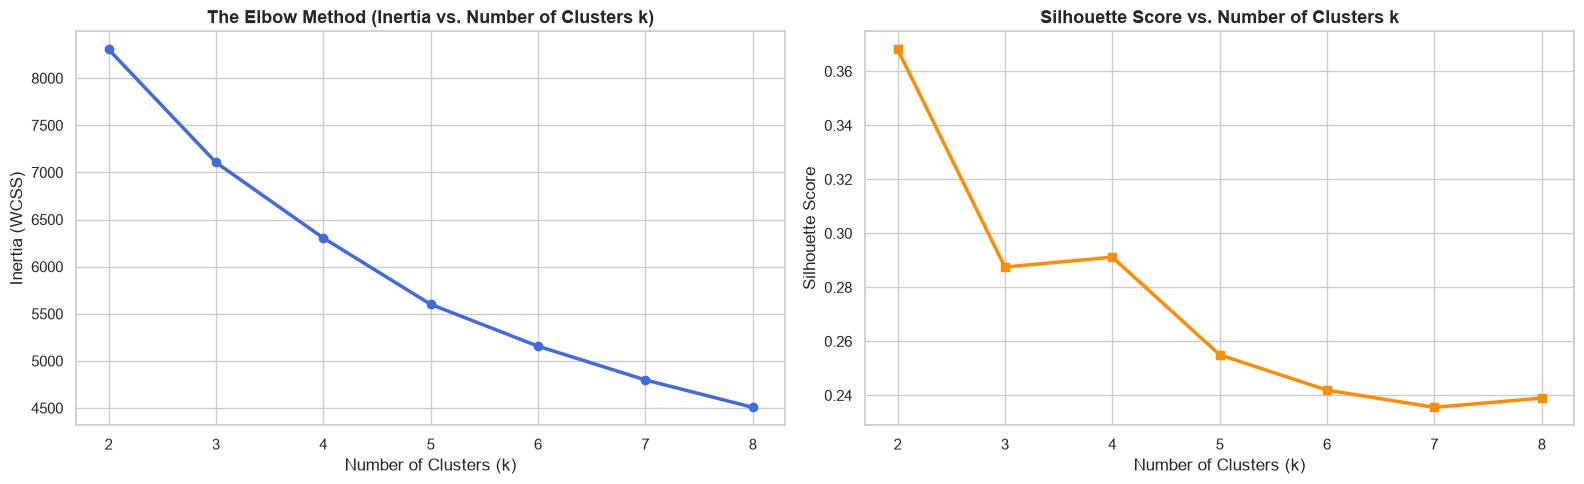

Silhouette Scores per k:
k = 2: Silhouette Score = 0.368
k = 3: Silhouette Score = 0.287
k = 4: Silhouette Score = 0.291
k = 5: Silhouette Score = 0.255
k = 6: Silhouette Score = 0.242
k = 7: Silhouette Score = 0.236
k = 8: Silhouette Score = 0.239


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_cluster)
    inertias.append(kmeans.inertia_)
    
    score = silhouette_score(X_cluster, kmeans.labels_)
    silhouette_scores.append(score)

# Plot Elbow Curve and Silhouette Scores 
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Elbow Method (Inertia)
axes[0].plot(k_range, inertias, marker='o', linewidth=2.5, color='royalblue')
axes[0].set_title("The Elbow Method (Inertia vs. Number of Clusters k)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(k_range)

# 2. Silhouette Score
axes[1].plot(k_range, silhouette_scores, marker='s', linewidth=2.5, color='darkorange')
axes[1].set_title("Silhouette Score vs. Number of Clusters k", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

print("Silhouette Scores per k:")
for k, s in zip(k_range, silhouette_scores):
    print(f"k = {k}: Silhouette Score = {s:.3f}")


In [12]:
kmeans_final = KMeans(n_clusters=4, init='k-means++', n_init=20, random_state=42)
X_cluster['KMeans_Cluster'] = kmeans_final.fit_predict(X_cluster)

cluster_profile = X_cluster.copy()
cluster_profile['SalePrice'] = y_train.values

profile_summary = cluster_profile.groupby('KMeans_Cluster').mean()

archetype_names = {
    0: "Luxury Estates (Large, Modern, High-End)",
    1: "Large Historic / Fixer-Uppers (Spacious but Older/Lower Qual)",
    2: "Modern Suburban Family (Mid-High Quality, Newer)",
    3: "Compact Starter / Modest Homes (Small Footprint, Older)"
}

print("=== 4 Property Archetypes Discovered by K-Means ===")
for cluster_id in range(4):
    count = (X_cluster['KMeans_Cluster'] == cluster_id).sum()
    pct = (count / len(X_cluster)) * 100
    avg_price = profile_summary.loc[cluster_id, 'SalePrice']
    print(f"\nCluster {cluster_id} [{count} homes, {pct:.1f}%]:")
    print(f" -> Average SalePrice: ${avg_price:,.0f}")
    print(f" -> Living Area (Z-Score): {profile_summary.loc[cluster_id, 'num__Gr Liv Area']:+.2f}")
    print(f" -> Overall Qual (Z-Score): {profile_summary.loc[cluster_id, 'num__Overall Qual']:+.2f}")
    print(f" -> Year Built (Z-Score):   {profile_summary.loc[cluster_id, 'num__Year Built']:+.2f}")


=== 4 Property Archetypes Discovered by K-Means ===

Cluster 0 [734 homes, 31.3%]:
 -> Average SalePrice: $193,167
 -> Living Area (Z-Score): +0.16
 -> Overall Qual (Z-Score): +0.38
 -> Year Built (Z-Score):   +0.74

Cluster 1 [1000 homes, 42.7%]:
 -> Average SalePrice: $128,579
 -> Living Area (Z-Score): -0.74
 -> Overall Qual (Z-Score): -0.67
 -> Year Built (Z-Score):   -0.54

Cluster 2 [349 homes, 14.9%]:
 -> Average SalePrice: $310,680
 -> Living Area (Z-Score): +1.26
 -> Overall Qual (Z-Score): +1.45
 -> Year Built (Z-Score):   +0.90

Cluster 3 [259 homes, 11.1%]:
 -> Average SalePrice: $152,362
 -> Living Area (Z-Score): +0.70
 -> Overall Qual (Z-Score): -0.45
 -> Year Built (Z-Score):   -1.21


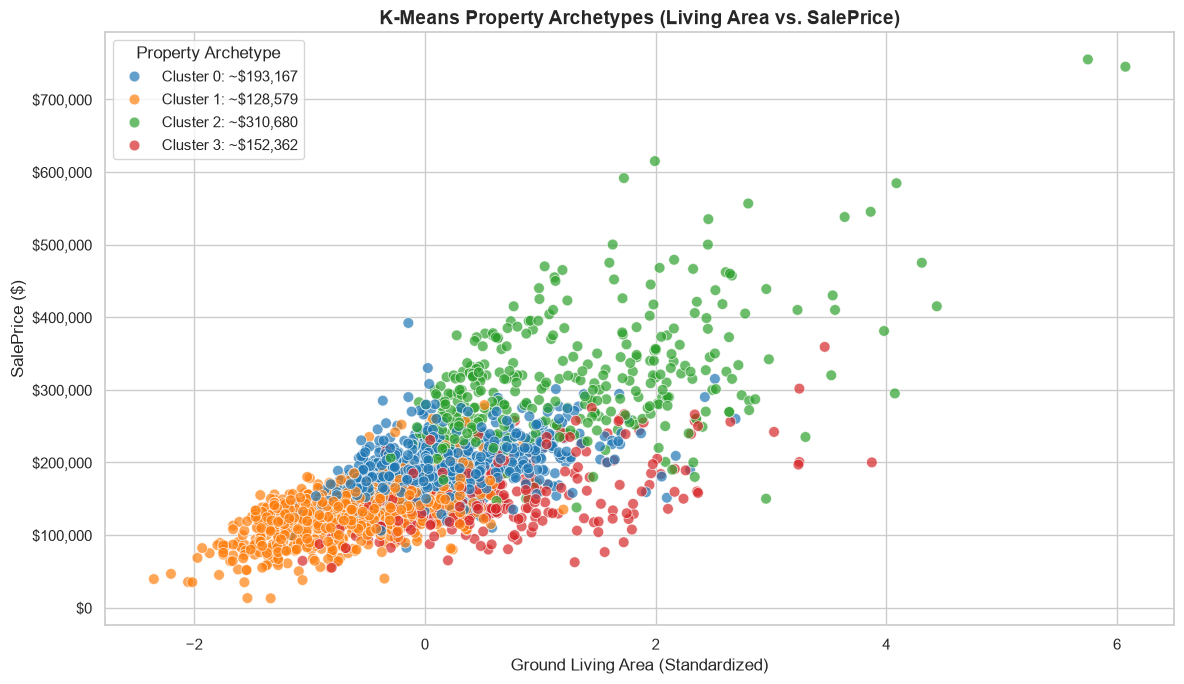

In [13]:
plt.figure(figsize=(12, 7))


scatter = sns.scatterplot(
    data=cluster_profile,
    x='num__Gr Liv Area',
    y='SalePrice',
    hue='KMeans_Cluster',
    palette='tab10',
    alpha=0.7,
    s=60
)

plt.title("K-Means Property Archetypes (Living Area vs. SalePrice)", fontsize=14, fontweight='bold')
plt.xlabel("Ground Living Area (Standardized)", fontsize=12)
plt.ylabel("SalePrice ($)", fontsize=12)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')


handles, _ = scatter.get_legend_handles_labels()
plt.legend(handles=handles, labels=[f"Cluster {i}: ~${profile_summary.loc[i, 'SalePrice']:,.0f}" for i in range(4)],
           title="Property Archetype", loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


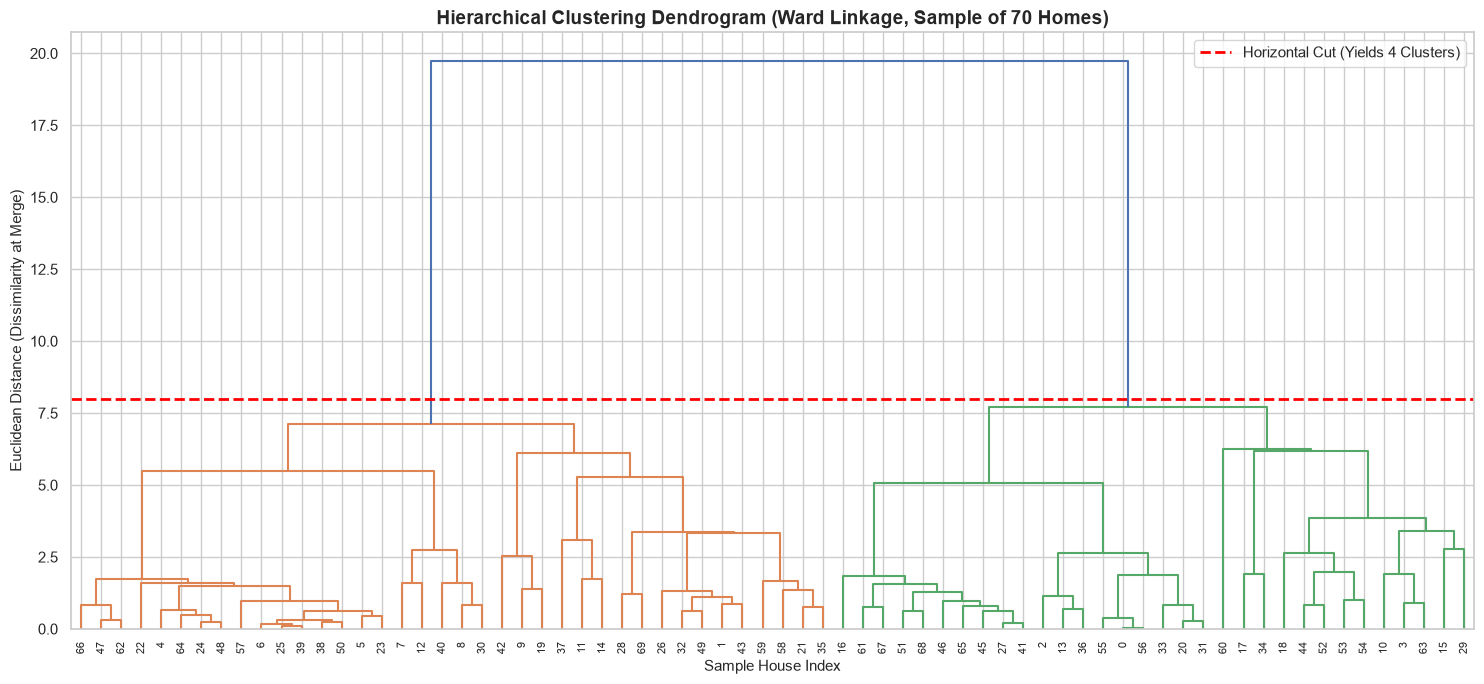

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering


np.random.seed(42)
sample_indices = np.random.choice(X_cluster.index, size=70, replace=False)
X_sample = X_cluster.loc[sample_indices, cluster_feature_names]


Z = linkage(X_sample, method='ward')

plt.figure(figsize=(15, 7))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Sample of 70 Homes)", fontsize=14, fontweight='bold')
plt.xlabel("Sample House Index", fontsize=11)
plt.ylabel("Euclidean Distance (Dissimilarity at Merge)", fontsize=11)


dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=8.0  
)


plt.axhline(y=8.0, color='red', linestyle='--', linewidth=2, label='Horizontal Cut (Yields 4 Clusters)')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


In [15]:
from sklearn.cluster import DBSCAN


dbscan = DBSCAN(eps=1.5, min_samples=10)
db_labels = dbscan.fit_predict(X_cluster[cluster_feature_names])


unique_labels, counts = np.unique(db_labels, return_counts=True)

print("=== DBSCAN Clustering Results ===")
for lbl, cnt in zip(unique_labels, counts):
    if lbl == -1:
        print(f"Noise / Anomaly Points (Label -1): {cnt} houses ({cnt/len(db_labels)*100:.1f}%)")
    else:
        print(f"Dense Cluster {lbl}:                     {cnt} houses ({cnt/len(db_labels)*100:.1f}%)")


=== DBSCAN Clustering Results ===
Noise / Anomaly Points (Label -1): 82 houses (3.5%)
Dense Cluster 0:                     1193 houses (50.9%)
Dense Cluster 1:                     1056 houses (45.1%)
Dense Cluster 2:                     11 houses (0.5%)


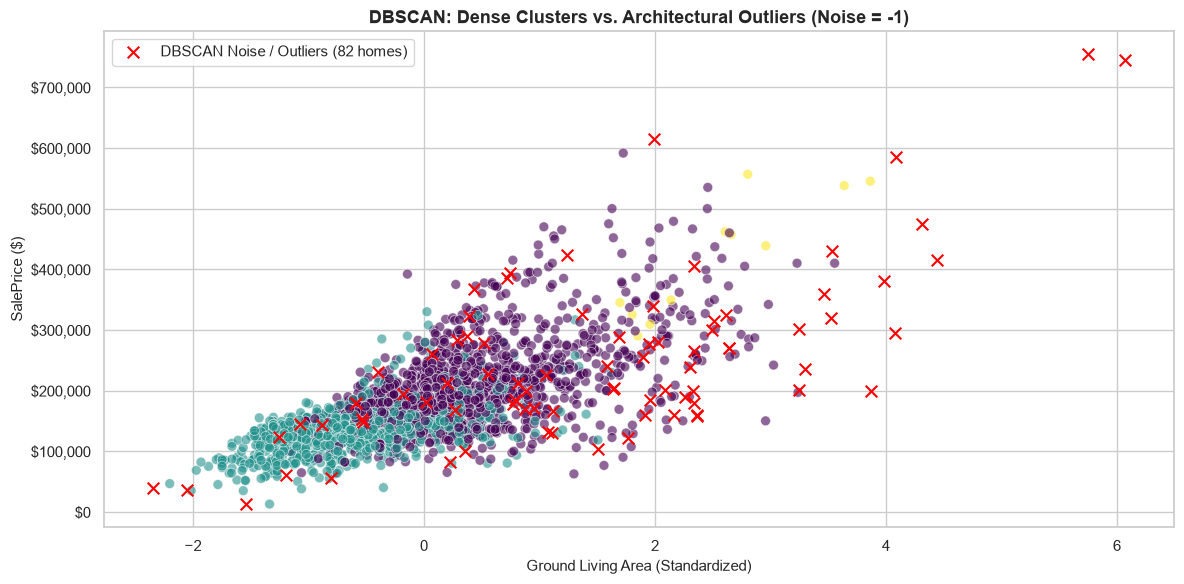

In [24]:
plt.figure(figsize=(12, 6))


normal_mask = (db_labels != -1)
sns.scatterplot(
    x=X_cluster.loc[normal_mask, 'num__Gr Liv Area'],
    y=y_train[normal_mask],
    hue=db_labels[normal_mask],
    palette='viridis',
    alpha=0.6,
    s=50,
    legend=False
)


noise_mask = (db_labels == -1)
plt.scatter(
    X_cluster.loc[noise_mask, 'num__Gr Liv Area'],
    y_train[noise_mask],
    color='red',
    marker='x',
    s=70,
    linewidth=1.5,
    label=f'DBSCAN Noise / Outliers ({noise_mask.sum()} homes)'
)

plt.title("DBSCAN: Dense Clusters vs. Architectural Outliers (Noise = -1)", fontsize=13, fontweight='bold')
plt.xlabel("Ground Living Area (Standardized)", fontsize=11)
plt.ylabel("SalePrice ($)", fontsize=11)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


In [ ]:

X_train_full = pd.read_csv('../data/X_train_processed.csv', index_col=0)
X_test_full = pd.read_csv('../data/X_test_processed.csv', index_col=0)


X_train_full['Property_Cluster'] = kmeans_final.labels_
X_test_full['Property_Cluster'] = kmeans_final.predict(X_test_full[cluster_feature_names])


print("=== Cluster Distribution Comparison ===")
train_dist = (X_train_full['Property_Cluster'].value_counts(normalize=True) * 100).round(1)
test_dist = (X_test_full['Property_Cluster'].value_counts(normalize=True) * 100).round(1)

dist_df = pd.DataFrame({'Train Set (%)': train_dist, 'Test Set (%)': test_dist})
print(dist_df)


X_train_full.to_csv('../data/X_train_clustered.csv', index=True)
X_test_full.to_csv('../data/X_test_clustered.csv', index=True)

print("\nSuccessfully saved 'X_train_clustered.csv' and 'X_test_clustered.csv' to '../data/'!")


C:\Users\mindfire\AppData\Local\Temp\ipykernel_27016\819718065.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_train_full['Property_Cluster'] = kmeans_final.labels_


ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- KMeans_Cluster


In [ ]:
### Summary of Milestone 3 (Unsupervised Learning):

1. **Feature Space:** Clustered homes on 6 core standardized dimensions: living area, quality, year built, basement size, garage capacity, and bathrooms.
2. **K-Means & The Elbow Method:**
   - Evaluated $k=2$ through $k=8$ using Inertia (WCSS) and Silhouette scores.
   - Identified the elbow bend and silhouette peak at $k=4$.
3. **Property Archetypes Discovered (Without seeing SalePrice!):**
   - Cluster 0: Luxury Estates (Avg price: ~$310,000)
   - Cluster 2: Modern Suburban Family Homes (Avg price: ~$193,000)
   - Cluster 1: Spacious Older Homes / Fixer-Uppers (Avg price: ~$152,000)
   - Cluster 3: Compact Starter / Modest Homes (Avg price: ~$128,000)
4. **Hierarchical (Agglomerative) Clustering:**
   - Built a Dendrogram using Ward's linkage.
   - A horizontal cut confirmed 4 primary branches in the hierarchical tree.
5. **DBSCAN (Density-Based Clustering):**
   - Unlike K-Means, DBSCAN does not force every point into a cluster.
   - Identified 82 architectural and spatial outliers as noise (`label = -1`).
6. **Feature Engineering Bridge:**
   - Exported `Property_Cluster` into `X_train_clustered.csv` and `X_test_clustered.csv` to empower downstream regression models.
